# Example of many-body perturbation theory (MBPT) in the GW approximation

In many-body perturbation theory the ground state of an interacting system is described by the one-body Green's function $G$, rather than the many-body wavefunction. The charge density, total energy and quasiparticle (electron addition and removal) energies all follow from $G$.

$G$ is found by solving Hedin's equations [1]. In the GW approximation the vertex function is neglected, and on the imaginary time ($\tau$) and imaginary frequency ($i\omega$) axes the equations read

$$P(x,x';\tau) = \sum_\sigma G_\sigma(x,x';\tau)\,G_\sigma(x',x;-\tau),$$

$$W(i\omega) = v + v\,P(i\omega)\,W(i\omega),$$

$$\Sigma_{\mathrm{xc},\sigma}(x,x';\tau) = -G_\sigma(x,x';\tau)\,W(x,x';\tau),$$

$$G_\sigma(i\omega) = G_{0,\sigma}(i\omega) + G_{0,\sigma}(i\omega)\,\big[\Sigma_\sigma(i\omega) - V_\sigma\big]\,G_\sigma(i\omega),$$

where $P$ is the irreducible polarisability, $W$ the screened interaction, $\Sigma_\sigma = v_\mathrm{h} + \Sigma_{\mathrm{xc},\sigma}$ the self-energy, and $V_\sigma$ the potential of the mean-field starting point $G_0$.

iDEA solves these equations with the GW space-time method of Rojas, Godby and Needs [2, 3]. The products ($P$ and $\Sigma$) are formed in real space and imaginary time, where they are local. $W$ and Dyson's equation are solved on the imaginary frequency axis, where they are also local. Three levels of self-consistency are available [4]:
- `G0W0`: one-shot, with the self-energy built from the Green's function of the starting point.
- `GW0`: $G$ iterated to self-consistency with $W$ fixed.
- `GW`: $G$ and $W$ both iterated to self-consistency. This is fully self-consistent GW, which conserves particle number and does not depend on the starting point.

**References**
1. L. Hedin, Phys. Rev. 139, A796 (1965).
2. H. N. Rojas, R. W. Godby, and R. J. Needs, Phys. Rev. Lett. 74, 1827 (1995).
3. M. M. Rieger, L. Steinbeck, I. D. White, H. N. Rojas, and R. W. Godby, Comput. Phys. Commun. 117, 211 (1999).
4. A. Stan, N. E. Dahlen, and R. van Leeuwen, J. Chem. Phys. 130, 114105 (2009).

## 1. Solving a two-electron atom

We take the two-electron (one up, one down) model atom, and solve it exactly, with Hartree-Fock, with one-shot G0W0 starting from Hartree-Fock, and with fully self-consistent GW.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import iDEA

x = np.linspace(-10, 10, 121)
v_ext = -2.0 / (abs(x) + 1.0)
v_int = iDEA.interactions.softened_interaction(x)
s = iDEA.system.System(x, v_ext, v_int, electrons="ud")

exact = iDEA.methods.interacting.solve(s, k=0)
hf = iDEA.methods.hartree_fock.solve(s, silent=True)
g0w0 = iDEA.methods.mbpt.solve(s, mode="G0W0", initial="hartree_fock", silent=True)
gw = iDEA.methods.mbpt.solve(s, mode="GW", silent=True)

iDEA.methods.interacting.solve: solving eigenproblem on CPU...


Each MBPT calculation returns an `iDEA.state.QuasiParticleState`. The usual observables accept it: the density is $n(x) = \sum_\sigma G_\sigma(x,x;\tau=0^-)$. `state.energy` holds the Galitskii-Migdal total energy. Fully self-consistent GW conserves the number of electrons exactly; one-shot G0W0 does not.

  method       energy    electrons   int |n - n_exact| dx
   exact    -1.718941   2.00000000               0.000000
      HF    -1.707919   2.00000000               0.030842
 G0W0@HF    -1.722472   1.99998405               0.003199
      GW    -1.722354   2.00000000               0.003199


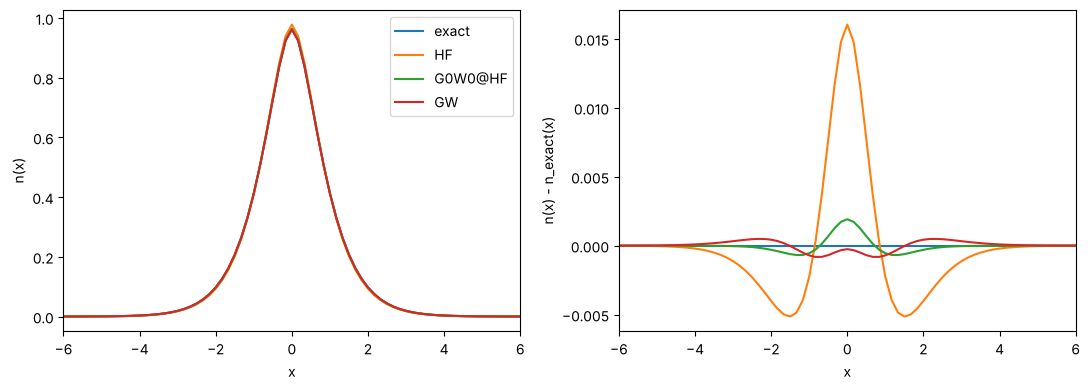

In [2]:
n_exact = iDEA.observables.density(s, state=exact)
results = {
    "exact": (exact.energy, n_exact),
    "HF": (iDEA.methods.hartree_fock.total_energy(s, hf), iDEA.observables.density(s, state=hf)),
    "G0W0@HF": (g0w0.energy, iDEA.observables.density(s, state=g0w0)),
    "GW": (gw.energy, iDEA.observables.density(s, state=gw)),
}
print(f"{'method':>8s} {'energy':>12s} {'electrons':>12s} {'int |n - n_exact| dx':>22s}")
for method, (E, n) in results.items():
    print(f"{method:>8s} {E:12.6f} {np.sum(n) * s.dx:12.8f} {np.sum(abs(n - n_exact)) * s.dx:22.6f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for method, (E, n) in results.items():
    ax[0].plot(s.x, n, label=method)
    ax[1].plot(s.x, n - n_exact, label=method)
ax[0].set_xlim(-6, 6)
ax[0].set_xlabel("x")
ax[0].set_ylabel("n(x)")
ax[0].legend()
ax[1].set_xlim(-6, 6)
ax[1].set_xlabel("x")
ax[1].set_ylabel("n(x) - n_exact(x)")
plt.tight_layout()
plt.show()

## 2. Inside the quasiparticle state

The state stores every quantity computed along the way. Each is held on the real-space grid together with an imaginary-time grid `state.tau` and an imaginary-frequency grid `state.omega`, both non-uniform. For each spin channel it holds:
- the Green's functions `G` and `G_iw`, and those of the starting point, `G0` and `G0_iw`;
- the self-energies `sigma_x`, `sigma_c`, `sigma_c_iw`, `sigma_xc_iw` and `sigma_iw`.

The polarisability `P` / `P_iw` and the screened interaction `W_iw` (with correlation part `W_c` / `W_c_iw`) are shared by both spin channels. Arrays are indexed as `[tau, x, x']` or `[omega, x, x']`.

iDEA.methods.mbpt.SpaceTimeGrid: 90 imaginary times in [-1.203e+02,1.203e+02], 78 imaginary frequencies in [0.000e+00,1.409e+03]
G: (90, 121, 121)  G_iw: (78, 121, 121)  W_iw: (78, 121, 121)


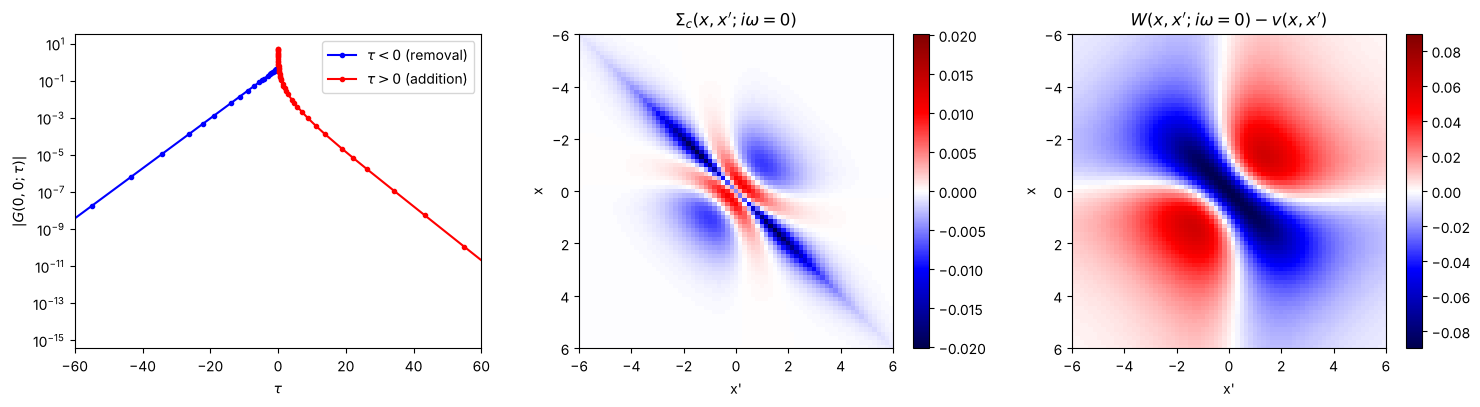

In [3]:
print(gw.grid)
print("G:", gw.up.G.shape, " G_iw:", gw.up.G_iw.shape, " W_iw:", gw.W_iw.shape)

# G(0,0;tau) decays exponentially. At large |tau| the decay rates give the quasiparticle HOMO and LUMO energies
# relative to the chemical potential.
i = np.argmin(abs(s.x))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].semilogy(gw.tau[gw.tau < 0], abs(gw.up.G[gw.tau < 0, i, i]), "b.-", label=r"$\tau < 0$ (removal)")
ax[0].semilogy(gw.tau[gw.tau > 0], abs(gw.up.G[gw.tau > 0, i, i]), "r.-", label=r"$\tau > 0$ (addition)")
ax[0].set_xlabel(r"$\tau$")
ax[0].set_ylabel(r"$|G(0,0;\tau)|$")
ax[0].set_xlim(-60, 60)
ax[0].legend()

# Exchange and correlation self-energies, and the correlation part of the screened interaction, at zero frequency.
extent = [s.x[0], s.x[-1], s.x[-1], s.x[0]]
for axis, A, title in [
    (ax[1], gw.up.sigma_c_iw[0].real, r"$\Sigma_c(x,x';i\omega=0)$"),
    (ax[2], gw.W_c_iw[0], r"$W(x,x';i\omega=0) - v(x,x')$"),
]:
    image = axis.imshow(A, extent=extent, cmap="seismic", vmin=-abs(A).max(), vmax=abs(A).max())
    axis.set_xlim(-6, 6)
    axis.set_ylim(6, -6)
    axis.set_title(title)
    axis.set_xlabel("x'")
    axis.set_ylabel("x")
    plt.colorbar(image, ax=axis)
plt.tight_layout()
plt.show()

The screened interaction on the imaginary axis interpolates between the bare interaction at high frequency and the most strongly screened interaction at $\omega = 0$:

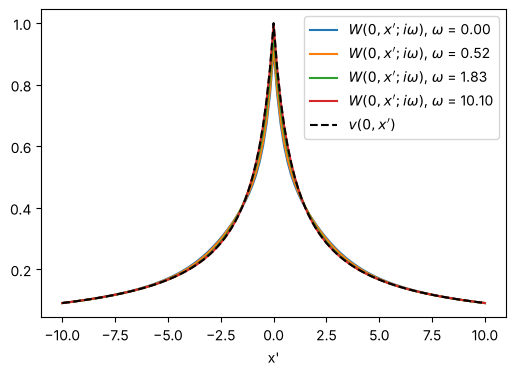

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
for w in [0.0, 0.5, 2.0, 10.0]:
    k = np.argmin(abs(gw.omega - w))
    ax.plot(s.x, gw.W_iw[k, i, :], label=rf"$W(0,x';i\omega)$, $\omega$ = {gw.omega[k]:.2f}")
ax.plot(s.x, s.v_int[i, :], "k--", label=r"$v(0,x')$")
ax.set_xlabel("x'")
ax.legend()
plt.show()

## 3. Hedin's equations, step by step

Each step of Hedin's equations is also available as a function, so the GW cycle can be followed one step at a time. Here we rebuild one-shot G0W0 starting from Hartree-Fock and compare it with `iDEA.methods.mbpt.solve`. The Hedin shift is turned off so that the chemical potential stays at the centre of the Hartree-Fock gap.

In [5]:
mbpt = iDEA.methods.mbpt
reference = mbpt.solve(s, mode="G0W0", initial="hartree_fock", hedin_shift=False, silent=True)
grid = reference.grid
mu = reference.up.mu0  # centre of the Hartree-Fock gap

# G0 from the Hartree-Fock orbitals, the polarisability, the screened interaction and the correlation self-energy.
G0, G0_iw = mbpt.non_interacting_green_function(s, grid, hf.up.energies, hf.up.orbitals, mu)
P, P_iw = mbpt.polarisability(s, grid, G0, G0)
W_c, W_c_iw, W_iw = mbpt.screened_interaction(s, grid, P_iw)
sigma_c, sigma_c_iw = mbpt.correlation_self_energy(s, grid, G0, W_c)

# Static part of the self-energy (Hartree and exchange), then Dyson's equation.
p0 = grid.interpolate(G0, 0.0)  # density matrix G0(x,x';0^-)
h = mbpt.kinetic_energy_operator(s) + mbpt.external_potential_operator(s)
h += np.diag(iDEA.observables.hartree_potential(s, 2.0 * np.diag(p0))) + mbpt.exchange_self_energy(s, p0) * s.dx
G, G_iw = mbpt.dyson_equation(s, grid, h, sigma_c_iw, mu)

n = 2.0 * np.diag(grid.interpolate(G, 0.0))
print("max |n - n(solve)| =", np.max(abs(n - iDEA.observables.density(s, state=reference))))

max |n - n(solve)| = 2.8671509610944668e-12


## 4. Quasiparticle energies

The state also contains quasiparticle energies in the static approximation, where the correlation self-energy is evaluated at the chemical potential ($i\omega = 0$). The ionisation potential is minus the energy of the highest occupied quasiparticle state. We compare it with the exact ionisation potential, $E(N-1) - E(N)$, and with Hartree-Fock (Koopmans' theorem).

In [6]:
s1 = iDEA.system.System(x, v_ext, v_int, electrons="u")
IP_exact = iDEA.methods.interacting.solve(s1, k=0).energy - exact.energy
print(f"IP exact       = {IP_exact:.4f}")
print(f"IP HF          = {-hf.up.energies[0]:.4f}")
print(f"IP G0W0@HF     = {-g0w0.up.energies[0]:.4f}")
print(f"IP GW          = {-gw.up.energies[0]:.4f}")

iDEA.methods.interacting.solve: solving eigenproblem on CPU...
IP exact       = 0.5783
IP HF          = 0.5759
IP G0W0@HF     = 0.5815
IP GW          = 0.5796
